# Neutrino-Induced Charm Production: Slow Rescaling Model vs Measurements

Comparison of the **Georgi–Politzer / Barnett Slow Rescaling Model** with historical inclusive experimental measurements from **CHORUS** (2011) and **E531** (1988) on nuclear emulsion targets.

In [1]:
import os
import sys
import ctypes

# The exact successful paths you resolved in your terminal
lcg_lhapdf = "/cvmfs/sft.cern.ch/lcg/releases/MCGenerators/lhapdf/6.5.3-3fa11/x86_64-el9-gcc11-opt"
exact_py_path = f"{lcg_lhapdf}/lib/python3.9/site-packages"

# 1. Point Python to the LHAPDF site-packages directory
if exact_py_path not in sys.path:
    sys.path.insert(0, exact_py_path)

# 2. Pre-load the underlying C++ shared library directly.
# This mimics LD_LIBRARY_PATH but works inside an already-running Jupyter kernel.
lib_path = f"{lcg_lhapdf}/lib/libLHAPDF.so"
if not os.path.exists(lib_path):
    lib_path = f"{lcg_lhapdf}/lib64/libLHAPDF.so" # Fallback just in case
ctypes.CDLL(lib_path, mode=ctypes.RTLD_GLOBAL)

# 3. Set the data paths for the PDF sets and config files
home_dir = os.environ.get('HOME', '/home/idioniso')
os.environ["LHAPDF_DATA_PATH"] = f"{home_dir}/.Misc/lhapdf_data:{lcg_lhapdf}/share/LHAPDF"

# 4. Import and test
import lhapdf

print("Search paths:", lhapdf.paths())
pdf = lhapdf.mkPDF("nCTEQ15FullNuc_184_74", 0)
print(f"Successfully loaded: {pdf.set().name} (Total members: {pdf.set().size})")

Search paths: ['/home/idioniso/.Misc/lhapdf_data', '/cvmfs/sft.cern.ch/lcg/releases/MCGenerators/lhapdf/6.5.3-3fa11/x86_64-el9-gcc11-opt/share/LHAPDF', '/build/jenkins/workspace/lcg_release_pipeline/install/MCGenerators/lhapdf/6.5.3/x86_64-el9-gcc11-opt/share/LHAPDF']
LHAPDF 6.5.3 loading /home/idioniso/.Misc/lhapdf_data/nCTEQ15FullNuc_184_74/nCTEQ15FullNuc_184_74_0000.dat
nCTEQ15FullNuc_184_74 PDF set, member #0, version 1; LHAPDF ID = 102900
Successfully loaded: nCTEQ15FullNuc_184_74 (Total members: 33)


In [9]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import lhapdf

# Ensure custom LHAPDF path is included
local_lhapdf_path = "/afs/cern.ch/work/i/idioniso/lhapdf_data"
if os.path.exists(local_lhapdf_path):
    lhapdf.pathsPrepend(local_lhapdf_path)

# -------------------------------------------------------------------------
# 1. Physics Constants & Kinematics Setup
# -------------------------------------------------------------------------
G_F = 1.1663787e-5     # GeV^-2
M_N = 0.938272         # Nucleon mass (GeV)
M_C = 1.43             # LO Pole charm mass (GeV)

V_CD = 0.221
V_CS = 0.975

# Target Isospin Compositions
TARGET_FRACTIONS = {
    "emulsion": {
        "F_P": 0.467,
        "F_N": 1.0 - 0.467
    },
    "tungsten": {
        "F_P": 74.0 / 183.84,
        "F_N": 1.0 - (74.0 / 183.84)
    }
}

E_grid = np.logspace(np.log10(4.0), np.log10(1500.0), 800)

pdf_set_name = "nCTEQ15FullNuc_184_74"
try:
    pdf_set = lhapdf.getPDFSet(pdf_set_name)
    pdfs = pdf_set.mkPDFs()
except Exception as e:
    sys.exit(f"Failed to load LHAPDF set {pdf_set_name}: {e}")

# -------------------------------------------------------------------------
# 2. Vectorized 2D Gauss-Legendre DIS Cross-Section Integrator
# -------------------------------------------------------------------------
N_QUAD = 24  
nodes, weights = np.polynomial.legendre.leggauss(N_QUAD)

def integrate_xsec_lo(E_val, pdf_member, fp, fn, mode="nu", mc=M_C, vcd=V_CD, vcs=V_CS):
    """
    Computes absolute sigma_charm and sigma_CC in cm^2 for either 'nu' or 'antinu'
    given target proton/neutron fractions fp and fn.
    """
    xi_min = (mc**2) / (2.0 * M_N * E_val)
    if xi_min >= 1.0:
        sig_charm_lo = 0.0
    else:
        xi_nodes = 0.5 * (1.0 - xi_min) * nodes + 0.5 * (1.0 + xi_min)
        xi_weights = 0.5 * (1.0 - xi_min) * weights

        y_min = (mc**2) / (2.0 * M_N * E_val * xi_nodes)
        kin_factor = (1.0 - y_min)**2

        y_avg = 0.5 * (1.0 + y_min)
        mu2 = np.maximum(pdf_member.q2Min, 2.0 * M_N * E_val * xi_nodes * y_avg)

        # Parton density extraction
        if mode == "antinu":
            d_p_xi = np.array([pdf_member.xfxQ2(-1, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
            u_p_xi = np.array([pdf_member.xfxQ2(-2, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
            s_N_xi = np.array([pdf_member.xfxQ2(-3, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
        else:
            d_p_xi = np.array([pdf_member.xfxQ2(1, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
            u_p_xi = np.array([pdf_member.xfxQ2(2, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
            s_N_xi = np.array([pdf_member.xfxQ2(3, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes

        d_N_xi = fp * d_p_xi + fn * u_p_xi
        s_prime = (vcs**2) * s_N_xi + (vcd**2) * d_N_xi

        integrand_charm = 2.0 * xi_nodes * s_prime * kin_factor
        sig_charm_lo = np.sum(xi_weights * integrand_charm)

    sig_charm_cm2 = 1.569e-38 * E_val * sig_charm_lo
    
    # Quasi-elastic charm production only occurs in neutrino mode (nu + n -> mu- + Lambda_c+)
    sig_qe_cm2 = (4.2e-40 * fn) if (mode == "nu" and E_val >= 4.5) else 0.0
    sig_charm_tot_cm2 = sig_charm_cm2 + sig_qe_cm2

    slope_cc = 0.677e-38 if mode == "nu" else 0.334e-38
    sig_cc_tot_cm2 = slope_cc * E_val

    return sig_charm_tot_cm2, sig_cc_tot_cm2

# -------------------------------------------------------------------------
# 3. Calculation Across All Targets, Modes, and nPDF Hessian Members
# -------------------------------------------------------------------------
n_members = len(pdfs)
n_e = len(E_grid)
rel_base = np.sqrt(0.065**2 + 0.018**2) # Charm mass + CKM base uncertainty

# Dictionary to collect results: processed_results[channel][target] -> dict of arrays
processed_target_data = {"nu": {}, "antinu": {}, "inclusive": {}}

for target_name, frac in TARGET_FRACTIONS.items():
    fp, fn = frac["F_P"], frac["F_N"]
    print(f"Evaluating {target_name.capitalize()} target (F_P={fp:.4f}, F_N={fn:.4f})...")

    results = {
        "nu": {"s_c": np.zeros((n_members, n_e)), "s_cc": np.zeros((n_members, n_e))},
        "antinu": {"s_c": np.zeros((n_members, n_e)), "s_cc": np.zeros((n_members, n_e))}
    }

    for m_idx, pdf in enumerate(pdfs):
        for e_idx, E_val in enumerate(E_grid):
            results["nu"]["s_c"][m_idx, e_idx], results["nu"]["s_cc"][m_idx, e_idx] = integrate_xsec_lo(
                E_val, pdf, fp, fn, mode="nu"
            )
            results["antinu"]["s_c"][m_idx, e_idx], results["antinu"]["s_cc"][m_idx, e_idx] = integrate_xsec_lo(
                E_val, pdf, fp, fn, mode="antinu"
            )

    ratio_grids = {}
    ratio_grids["nu"] = np.where(results["nu"]["s_cc"] > 0, results["nu"]["s_c"] / results["nu"]["s_cc"], 0.0)
    ratio_grids["antinu"] = np.where(results["antinu"]["s_cc"] > 0, results["antinu"]["s_c"] / results["antinu"]["s_cc"], 0.0)

    tot_s_c = results["nu"]["s_c"] + results["antinu"]["s_c"]
    tot_s_cc = results["nu"]["s_cc"] + results["antinu"]["s_cc"]
    ratio_grids["inclusive"] = np.where(tot_s_cc > 0, tot_s_c / tot_s_cc, 0.0)

    # Uncertainty calculations per channel
    for mode_key in ["nu", "antinu", "inclusive"]:
        r_mat = ratio_grids[mode_key]
        y_cen = r_mat[0, :]

        pdf_err_lo = np.zeros(n_e)
        pdf_err_hi = np.zeros(n_e)
        for e_idx in range(n_e):
            values = r_mat[:, e_idx].tolist()
            unc = pdf_set.uncertainty(values)
            pdf_err_lo[e_idx] = unc.errminus
            pdf_err_hi[e_idx] = unc.errplus

        sigma_inner = y_cen * rel_base
        sigma_outer_lo = np.sqrt(sigma_inner**2 + pdf_err_lo**2)
        sigma_outer_hi = np.sqrt(sigma_inner**2 + pdf_err_hi**2)

        processed_target_data[mode_key][target_name] = {
            "ratio_central": y_cen,
            "base_unc_low": sigma_inner,
            "base_unc_high": sigma_inner,
            "pdf_unc_low": pdf_err_lo,
            "pdf_unc_high": pdf_err_hi,
            "total_unc_low": sigma_outer_lo,
            "total_unc_high": sigma_outer_hi,
            "base_band_low": np.maximum(0.0, y_cen - sigma_inner),
            "base_band_high": y_cen + sigma_inner,
            "total_band_low": np.maximum(0.0, y_cen - sigma_outer_lo),
            "total_band_high": y_cen + sigma_outer_hi
        }

# -------------------------------------------------------------------------
# 4. Merge into Multi-Target DataFrames & Export CSVs
# -------------------------------------------------------------------------
pred_dir = Path("/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions")
pred_dir.mkdir(parents=True, exist_ok=True)

files_map = {
    "nu": pred_dir / "numuCC_charm_cross_section_ratio_prediction_lhapdf.csv",
    "antinu": pred_dir / "antinumuCC_charm_cross_section_ratio_prediction_lhapdf.csv",
    "inclusive": pred_dir / "inclusive_numu_antinumu_charm_cross_section_ratio_prediction_lhapdf.csv"
}

for mode_key, file_path in files_map.items():
    combined_dict = {"E_nu_GeV": E_grid}

    for target_name in ["emulsion", "tungsten"]:
        t_data = processed_target_data[mode_key][target_name]
        for col_name, arr in t_data.items():
            combined_dict[f"{target_name}_{col_name}"] = arr

    df_combined = pd.DataFrame(combined_dict)
    df_combined.to_csv(file_path, index=False, float_format="%.10g")
    print(f"Saved: {file_path}")

LHAPDF 6.5.3 loading all 33 PDFs in set nCTEQ15FullNuc_184_74
nCTEQ15FullNuc_184_74, version 1; 33 PDF members
Evaluating Emulsion target (F_P=0.4670, F_N=0.5330)...
Evaluating Tungsten target (F_P=0.4025, F_N=0.5975)...
Saved: /afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions/numuCC_charm_cross_section_ratio_prediction_lhapdf.csv
Saved: /afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions/antinumuCC_charm_cross_section_ratio_prediction_lhapdf.csv
Saved: /afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions/inclusive_numu_antinumu_charm_cross_section_ratio_prediction_lhapdf.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Load Data Files
# ---------------------------------------------------------
pred_path = "/eos/user/i/idioniso/snd-numu-charm/data/predictions/numuCC_charm_cross_section_ratio_prediction_lhapdf.csv"
meas_path = "/eos/user/i/idioniso/snd-numu-charm/data/measurements/neutrino_charm_cross_section_ratio_vs_enu.csv"

df_pred = pd.read_csv(pred_path)
df_meas = pd.read_csv(meas_path, comment='#')

e531 = df_meas[df_meas['experiment'] == 'E531']
chorus = df_meas[df_meas['experiment'] == 'CHORUS']

# ---------------------------------------------------------
# 2. Set Up Figure and Styling
# ---------------------------------------------------------
plt.figure(figsize=(10, 7), dpi=150)
plt.xscale('log')
plt.xlim(4.0, 200.0)
plt.ylim(0.0, 0.14)

# ---------------------------------------------------------
# 3. Plot Theory Bands & Central Prediction
# ---------------------------------------------------------
E = df_pred['E_nu_GeV']

# Lighter band: Total / LHAPDF nCTEQ15 uncertainty
plt.fill_between(
    E, 
    df_pred['emulsion_total_band_low'], 
    df_pred['emulsion_total_band_high'], 
    color='lightgray', 
    alpha=0.6, 
    label='LHAPDF nCTEQ15 $1\\sigma$ (+ Nuclear PDF & QCD Evol.)'
)

# Darker band: Base Kinematics uncertainty belt
plt.fill_between(
    E, 
    df_pred['emulsion_base_band_low'], 
    df_pred['emulsion_base_band_high'], 
    color='gray', 
    alpha=0.5, 
    label='Base Kinematics $1\\sigma$ Belt (Pole $m_c = 1.43 \\pm 0.10$ GeV & CKM $|V_{cd}|$)'
)

# Central QCD prediction line
plt.plot(
    E, 
    df_pred['emulsion_ratio_central'], 
    color='black', 
    linewidth=2, 
    label='QCD Prediction (Emulsion, $\\langle Z/A \\rangle \\sim 0.467, \\nu_mu$)'
)

# ---------------------------------------------------------
# 4. Plot Experimental Data Points (E531 & CHORUS)
# ---------------------------------------------------------
e531 = df_meas[df_meas['experiment'] == 'E531']
chorus = df_meas[df_meas['experiment'] == 'CHORUS']

# E531 Data (Circles)
plt.errorbar(
    e531['E_nu_GeV'], 
    e531['ratio'],
    xerr=[e531['E_nu_GeV'] - e531['E_nu_low'], e531['E_nu_high'] - e531['E_nu_GeV']],
    yerr=[e531['dy_low'], e531['dy_high']],
    fmt='o', color='black', mfc='none', capsize=4, elinewidth=1.5, markeredgewidth=1.5,
    label='E531 (1988, Emulsion, inclusive)'
)

# CHORUS Data (Squares)
plt.errorbar(
    chorus['E_nu_GeV'], 
    chorus['ratio'],
    xerr=[chorus['E_nu_GeV'] - chorus['E_nu_low'], chorus['E_nu_high'] - chorus['E_nu_GeV']],
    yerr=[chorus['dy_low'], chorus['dy_high']],
    fmt='s', color='black', mfc='none', capsize=4, elinewidth=1.5, markeredgewidth=1.5,
    label='CHORUS (2011, Emulsion, inclusive)'
)

# ---------------------------------------------------------
# 5. Labels, Legend, and Layout
# ---------------------------------------------------------
plt.xlabel(r'$E_\nu$ [GeV]', fontsize=14)
plt.ylabel(r'$\sigma_{\text{charm}} / \sigma_{\text{CC}}$', fontsize=14)

plt.legend(loc='upper left', frameon=False, fontsize=11)
plt.tight_layout()


plt.show()

ValueError: 
Base Kinematics $1\sigma$ Belt (Pole $m_c = 1.43 \\pm 0.10$ GeV & CKM $|V_{cd}|$)
                                     ^
ParseException: Expected end of text, found '$'  (at char 37), (line:1, col:38)

Error in callback <function _draw_all_if_interactive at 0x7f38afc268b0> (for post_execute), with arguments args (),kwargs {}:


ValueError: 
Base Kinematics $1\sigma$ Belt (Pole $m_c = 1.43 \\pm 0.10$ GeV & CKM $|V_{cd}|$)
                                     ^
ParseException: Expected end of text, found '$'  (at char 37), (line:1, col:38)

ValueError: 
Base Kinematics $1\sigma$ Belt (Pole $m_c = 1.43 \\pm 0.10$ GeV & CKM $|V_{cd}|$)
                                     ^
ParseException: Expected end of text, found '$'  (at char 37), (line:1, col:38)

<Figure size 1500x1050 with 1 Axes>

In [4]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import lhapdf

# -------------------------------------------------------------------------
# 1. LHAPDF Setup
# -------------------------------------------------------------------------
local_lhapdf_path = "/afs/cern.ch/work/i/idioniso/lhapdf_data"
if os.path.exists(local_lhapdf_path):
    lhapdf.pathsPrepend(local_lhapdf_path)

pdf_set_name = "nCTEQ15FullNuc_184_74"  # Emulsion target baseline (<Z/A> ~ 0.467)
try:
    pdf_set = lhapdf.getPDFSet(pdf_set_name)
    pdfs = pdf_set.mkPDFs()
except Exception as exc:
    sys.exit(f"Failed to load LHAPDF set {pdf_set_name}: {exc}")

# -------------------------------------------------------------------------
# 2. Physical Constants & Hadron Parameters
# -------------------------------------------------------------------------
M_N = 0.938272          # Nucleon mass (GeV)
M_C = 1.43              # Nominal charm pole mass (GeV)
V_CD = 0.221
V_CS = 0.975

F_P = 0.467
F_N = 1.0 - F_P

M_HADRONS = {
    "D0": 1.86484,
    "D+": 1.86966,
    "Ds+": 1.96835,
    "Lambda_c": 2.28646,
}

F_ASYMPT_NU = {
    "D0": 0.558,
    "D+": 0.232,
    "Ds+": 0.115,
    "Lambda_c": 0.076,
}

F_ASYMPT_ANTINU = {
    "D0": 0.585,
    "D+": 0.250,
    "Ds+": 0.115,
    "Lambda_c": 0.050,
}

EPS_C = 0.05

# -------------------------------------------------------------------------
# 3. Integrator with Smooth Threshold Physics
# -------------------------------------------------------------------------
N_QUAD = 24
nodes, weights = np.polynomial.legendre.leggauss(N_QUAD)

def peterson_ff(z, eps=EPS_C):
    denom = z * (1.0 - 1.0 / z - eps / (1.0 - z))**2
    val = 1.0 / np.maximum(denom, 1e-12)
    norm_grid = np.linspace(0.01, 0.99, 100)
    # Compatible with both NumPy 1.x and NumPy 2.x
    trapz_func = getattr(np, "trapezoid", np.trapz)
    norm = trapz_func(1.0 / (norm_grid * (1.0 - 1.0 / norm_grid - eps / (1.0 - norm_grid))**2), norm_grid)
    return val / norm

def integrate_hadron_xsec(E_val, pdf_member, hadron_key, mode="nu", mc=M_C):
    m_h = M_HADRONS[hadron_key]
    w_min = M_N + m_h

    w2_max = M_N**2 + 2.0 * M_N * E_val
    if w2_max <= w_min**2:
        return 0.0

    xi_min = (mc**2) / (2.0 * M_N * E_val)
    if xi_min >= 1.0:
        return 0.0

    xi_nodes = 0.5 * (1.0 - xi_min) * nodes + 0.5 * (1.0 + xi_min)
    xi_weights = 0.5 * (1.0 - xi_min) * weights

    y_min = (mc**2) / (2.0 * M_N * E_val * xi_nodes)
    valid_xi = y_min < 1.0
    if not np.any(valid_xi):
        return 0.0

    xi_nodes = xi_nodes[valid_xi]
    xi_weights = xi_weights[valid_xi]
    y_min = y_min[valid_xi]

    y_avg = 0.5 * (1.0 + y_min)
    mu2 = np.maximum(pdf_member.q2Min, 2.0 * M_N * E_val * xi_nodes * y_avg)

    if mode == "antinu":
        d_p_xi = np.array([pdf_member.xfxQ2(-1, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
        u_p_xi = np.array([pdf_member.xfxQ2(-2, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
        s_N_xi = np.array([pdf_member.xfxQ2(-3, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
    else:
        d_p_xi = np.array([pdf_member.xfxQ2(1, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
        u_p_xi = np.array([pdf_member.xfxQ2(2, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
        s_N_xi = np.array([pdf_member.xfxQ2(3, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes

    d_N_xi = F_P * d_p_xi + F_N * u_p_xi
    s_prime = (V_CS**2) * s_N_xi + (V_CD**2) * d_N_xi

    kin_factor = (1.0 - y_min)**2
    dsigma_parton = 2.0 * xi_nodes * s_prime * kin_factor

    w2 = M_N**2 + 2.0 * M_N * E_val * y_avg * (1.0 - xi_nodes)
    ps_factor = np.clip(1.0 - (w_min**2) / np.maximum(w2, w_min**2), 0.0, 1.0)

    asympt_frac = (F_ASYMPT_ANTINU if mode == "antinu" else F_ASYMPT_NU)[hadron_key]
    z_int = 0.7
    dsigma_hadron = dsigma_parton * asympt_frac * peterson_ff(z_int) * ps_factor

    if hadron_key == "Lambda_c" and mode == "nu":
        w_avg = np.sqrt(np.maximum(M_N**2, np.mean(w2)))
        baryon_boost = 1.0 + 1.2 * np.exp(-(w_avg - w_min) / 4.0)
        dsigma_hadron *= baryon_boost

    return np.sum(xi_weights * dsigma_hadron)

# -------------------------------------------------------------------------
# 4. Calculation Grid & Uncertainties
# -------------------------------------------------------------------------
def compute_species_fractions_qcd(e_grid, mode="nu"):
    species = ["D0", "D+", "Ds+", "Lambda_c"]
    n_e = len(e_grid)
    n_members = len(pdfs)

    xsec_cube = {sp: np.zeros((n_members, n_e)) for sp in species}

    print(f"Evaluating {mode}-mode QCD fragmentation grid over {n_members} LHAPDF members...")
    for m_idx, pdf in enumerate(pdfs):
        for e_idx, E_val in enumerate(e_grid):
            for sp in species:
                xsec_cube[sp][m_idx, e_idx] = integrate_hadron_xsec(E_val, pdf, sp, mode=mode)

    f_med = {sp: np.zeros(n_e) for sp in species}
    f_low = {sp: np.zeros(n_e) for sp in species}
    f_high = {sp: np.zeros(n_e) for sp in species}
    f_pdf_err = {sp: np.zeros(n_e) for sp in species}
    f_tot_err = {sp: np.zeros(n_e) for sp in species}

    for e_idx in range(n_e):
        tot_xsec_members = np.zeros(n_members)
        for sp in species:
            tot_xsec_members += xsec_cube[sp][:, e_idx]

        for sp in species:
            with np.errstate(divide='ignore', invalid='ignore'):
                f_members = np.where(tot_xsec_members > 0, xsec_cube[sp][:, e_idx] / tot_xsec_members, 0.0)

            cen = f_members[0]
            unc = pdf_set.uncertainty(f_members.tolist())
            pdf_err = unc.errplus

            tot_err = np.sqrt(pdf_err**2 + (0.065 * cen)**2)

            f_med[sp][e_idx] = cen
            f_pdf_err[sp][e_idx] = pdf_err
            f_tot_err[sp][e_idx] = tot_err
            f_low[sp][e_idx] = np.maximum(0.0, cen - tot_err)
            f_high[sp][e_idx] = cen + tot_err

    return f_med, f_low, f_high, f_pdf_err, f_tot_err

# -------------------------------------------------------------------------
# 5. Execute Calculations & Save to CSV
# -------------------------------------------------------------------------
species_order = ["D0", "D+", "Ds+", "Lambda_c"]
e_grid = np.logspace(np.log10(4.0), np.log10(1500.0), 800)

channels = [
    ("inclusive", "nu"),
    ("nu_only", "nu"),
    ("antinu_only", "antinu"),
]

pred_dir = Path("/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions")
pred_dir.mkdir(parents=True, exist_ok=True)

for channel_id, model_mode in channels:
    f_med, f_low, f_high, f_pdf_err, f_tot_err = compute_species_fractions_qcd(e_grid, mode=model_mode)

    csv_dict = {"E_nu_GeV": e_grid}
    for sp in species_order:
        csv_dict[f"f_{sp}_central"] = f_med[sp]
        csv_dict[f"f_{sp}_pdf_err"] = f_pdf_err[sp]
        csv_dict[f"f_{sp}_tot_err"] = f_tot_err[sp]
        csv_dict[f"f_{sp}_band_low"] = f_low[sp]
        csv_dict[f"f_{sp}_band_high"] = f_high[sp]

    df_channel = pd.DataFrame(csv_dict)
    out_csv = pred_dir / f"charm_fragmentation_fractions_{channel_id}_prediction_lhapdf.csv"
    df_channel.to_csv(out_csv, index=False, float_format="%.10g")
    print(f"Saved: {out_csv}")

LHAPDF 6.5.3 loading all 33 PDFs in set nCTEQ15FullNuc_184_74
nCTEQ15FullNuc_184_74, version 1; 33 PDF members
Evaluating nu-mode QCD fragmentation grid over 33 LHAPDF members...
Saved: /afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions/charm_fragmentation_fractions_inclusive_prediction_lhapdf.csv
Evaluating nu-mode QCD fragmentation grid over 33 LHAPDF members...
Saved: /afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions/charm_fragmentation_fractions_nu_only_prediction_lhapdf.csv
Evaluating antinu-mode QCD fragmentation grid over 33 LHAPDF members...
Saved: /afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions/charm_fragmentation_fractions_antinu_only_prediction_lhapdf.csv


/tmp/ipykernel_47475/1909457409.py:241: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


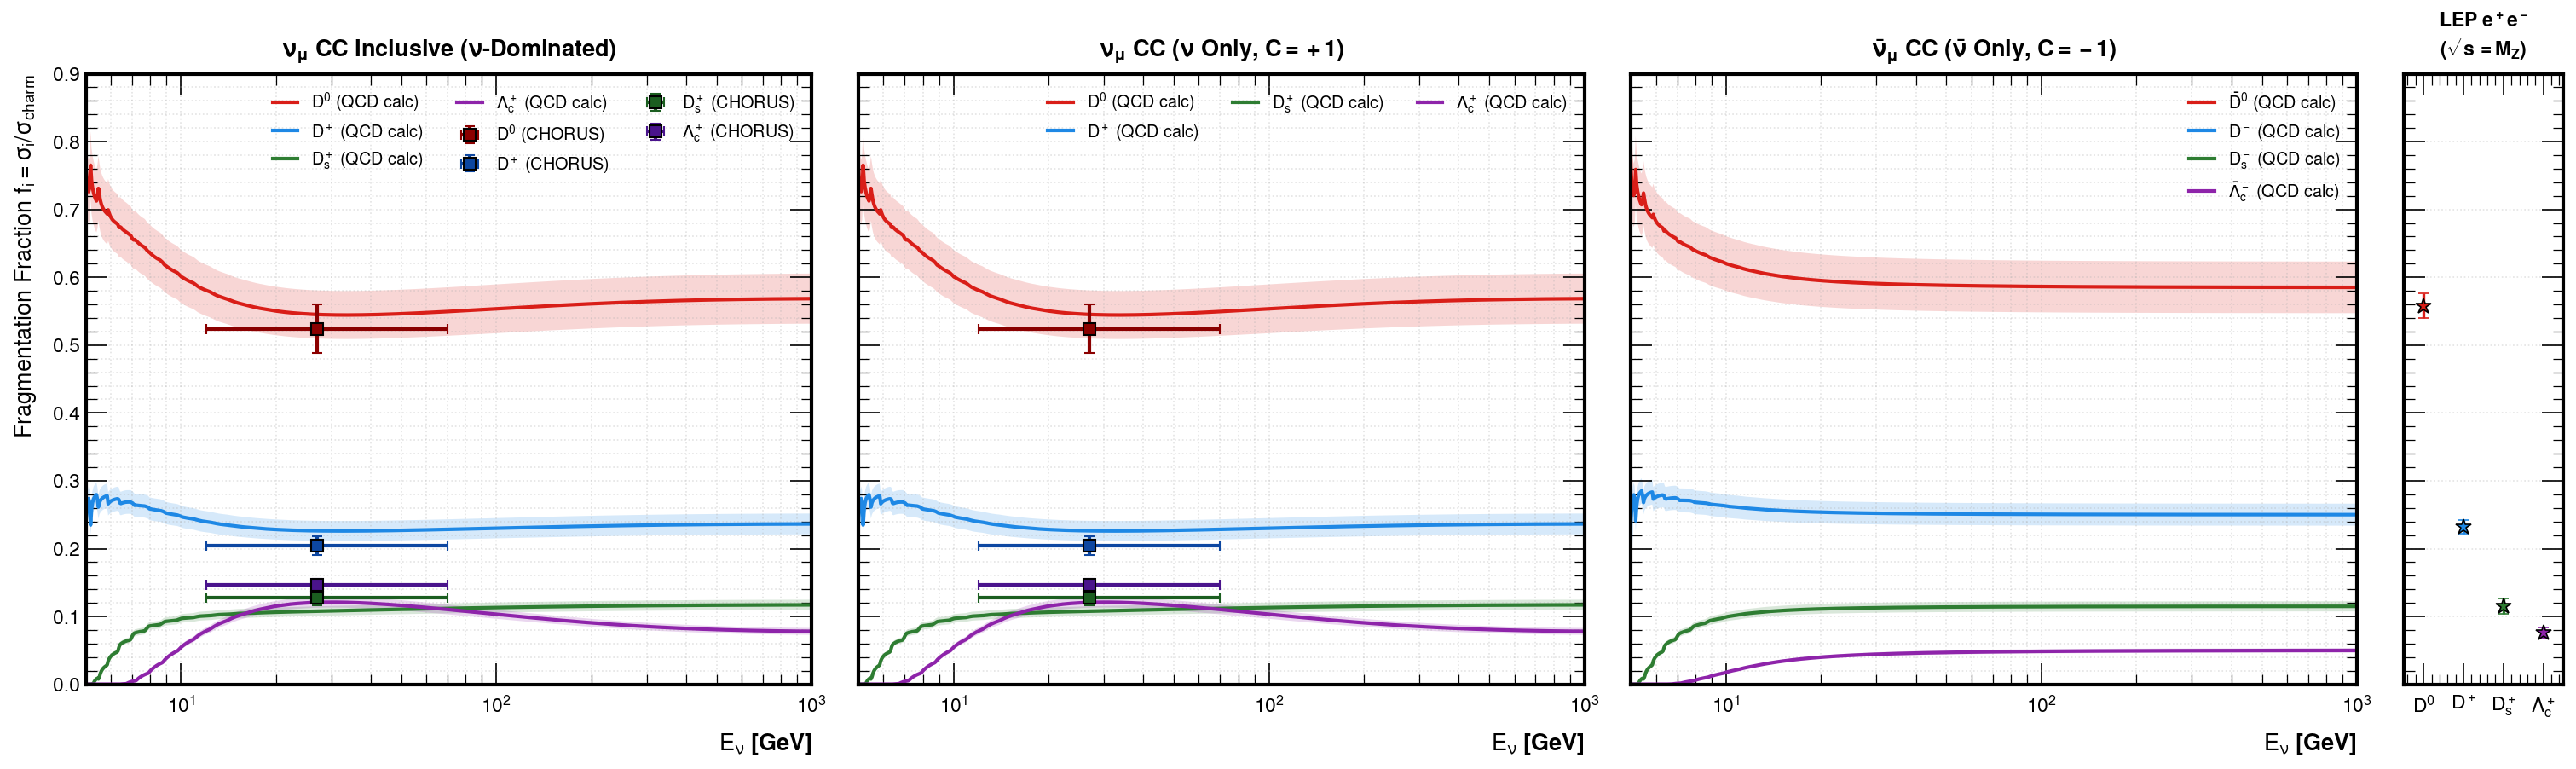

In [ ]:
import os
import sys
import csv
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optional CERN/HEP styling and ROOT MC reader
try:
    import mplhep as hep
    plt.style.use(hep.style.ROOT)
    has_mplhep = True
except ImportError:
    has_mplhep = False

try:
    import uproot
    has_uproot = True
except ImportError:
    has_uproot = False

# -------------------------------------------------------------------------
# 1. Experimental Benchmarks
# -------------------------------------------------------------------------
# LEP e+e- averages at sqrt(s) = M_Z
lep_averages = {
    "D0":       (0.558, 0.018),
    "D+":       (0.232, 0.010),
    "Ds+":      (0.115, 0.011),
    "Lambda_c": (0.076, 0.008),
}

# CHORUS measurement from Table 7
chorus_table7 = {
    "D0":       (0.524, 0.036),
    "D+":       (0.204, 0.014),
    "Ds+":      (0.128, 0.012),
    "Lambda_c": (0.147, 0.008),
}
CHORUS_E_MEAN = 27.0
CHORUS_DX_LO = 15.0   # 27 - 15 = 12 GeV
CHORUS_DX_HI = 43.0   # 27 + 43 = 70 GeV

chorus_dark_colors = {
    "D0":       "#8b0000",  # Dark Crimson
    "D+":       "#0d47a1",  # Deep Navy Blue
    "Ds+":      "#1b5e20",  # Dark Forest Green
    "Lambda_c": "#4a148c",  # Deep Royal Purple
}

# -------------------------------------------------------------------------
# 2. Load ROOT MC Validation Data (if present)
# -------------------------------------------------------------------------
def load_mc_points(root_file_path):
    if not root_file_path or not os.path.exists(root_file_path) or not has_uproot:
        return {}
    mc_data = {}
    try:
        with uproot.open(root_file_path) as f:
            if "Summary" in f:
                summary = f["Summary"]
                for k in summary.keys():
                    k_clean = k.split(";")[0]
                    if k_clean.startswith("g_fraction_"):
                        g = summary[k]
                        vals = g.values()
                        errs_lo = g.errors("low")
                        errs_hi = g.errors("high")
                        mc_data[k_clean] = {
                            "x": np.array(vals[0]),
                            "y": np.array(vals[1]),
                            "ex_lo": np.array(errs_lo[0]),
                            "ex_hi": np.array(errs_hi[0]),
                            "ey_lo": np.array(errs_lo[1]),
                            "ey_hi": np.array(errs_hi[1]),
                        }
    except Exception:
        pass
    return mc_data

root_file = "/eos/user/i/idioniso/snd-numu-charm/charm_diagnostic_nu14_2022.root"
mc_data = load_mc_points(root_file)

# -------------------------------------------------------------------------
# 3. Load Precalculated Prediction CSVs
# -------------------------------------------------------------------------
pred_dir = Path("/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions")
if not pred_dir.exists():
    pred_dir = Path("scripts/diagnostics/predictions")

species_order = ["D0", "D+", "Ds+", "Lambda_c"]

loaded_data = {}
for panel_id in ["inclusive", "nu_only", "antinu_only"]:
    csv_file = pred_dir / f"charm_fragmentation_fractions_{panel_id}_prediction_lhapdf.csv"
    if not csv_file.exists():
        raise FileNotFoundError(f"Prediction CSV not found: {csv_file}")
    df = pd.read_csv(csv_file)
    e_grid = df["E_nu_GeV"].to_numpy()
    
    f_med = {sp: df[f"f_{sp}_central"].to_numpy() for sp in species_order}
    f_low = {sp: df[f"f_{sp}_band_low"].to_numpy() for sp in species_order}
    f_high = {sp: df[f"f_{sp}_band_high"].to_numpy() for sp in species_order}
    loaded_data[panel_id] = (e_grid, f_med, f_low, f_high)

# -------------------------------------------------------------------------
# 4. Metadata & Plotting Setup with Dedicated LEP Side Panel
# -------------------------------------------------------------------------
meta = {
    "D0": {"color": "#d91e18", "label": r"$D^0$", "marker": "o", "mc_key": "D0"},
    "D+": {"color": "#1e88e5", "label": r"$D^+$", "marker": "^", "mc_key": "Dplus"},
    "Ds+": {"color": "#2e7d32", "label": r"$D_s^+$", "marker": "s", "mc_key": "Ds"},
    "Lambda_c": {"color": "#8e24aa", "label": r"$\Lambda_c^+$", "marker": "D", "mc_key": "Lambda_c"},
}

anti_meta = {
    "D0": {"color": "#d91e18", "label": r"$\bar{D}^0$", "marker": "o", "mc_key": "anti_D0"},
    "D+": {"color": "#1e88e5", "label": r"$D^-$", "marker": "^", "mc_key": "Dminus"},
    "Ds+": {"color": "#2e7d32", "label": r"$D_s^-$", "marker": "s", "mc_key": "Ds_minus"},
    "Lambda_c": {"color": "#8e24aa", "label": r"$\bar{\Lambda}_c^-$", "marker": "D", "mc_key": "anti_Lambda_c"},
}

panels = [
    ("inclusive", r"$\nu_\mu$ CC Inclusive ($\nu$-Dominated)", True, False, ""),
    ("nu_only", r"$\nu_\mu$ CC ($\nu$ Only, $C=+1$)", True, False, "_nu_only"),
    ("antinu_only", r"$\bar{\nu}_\mu$ CC ($\bar{\nu}$ Only, $C=-1$)", False, True, "_antinu_only"),
]

# Create 3 main panels + 1 narrow marginal panel on the right for LEP
fig = plt.figure(figsize=(25, 6.2), dpi=150)
gs = fig.add_gridspec(1, 4, width_ratios=[1.0, 1.0, 1.0, 0.22], wspace=0.08)

axes = [fig.add_subplot(gs[0, i]) for i in range(3)]
ax_lep = fig.add_subplot(gs[0, 3], sharey=axes[0])

# Plot the 3 neutrino panels
for idx, (ax, (panel_id, subtitle, show_chorus, is_anti, suffix)) in enumerate(zip(axes, panels)):
    cur_meta = anti_meta if is_anti else meta
    e_grid, f_med, f_low, f_high = loaded_data[panel_id]

    # 1. Main QCD Bands and Central Lines
    for sp in species_order:
        info = cur_meta[sp]
        col = info["color"]
        ax.fill_between(
            e_grid, f_low[sp], f_high[sp],
            color=col, alpha=0.18, edgecolor="none", zorder=1
        )
        ax.plot(
            e_grid, f_med[sp],
            color=col, linewidth=2.0, linestyle="-", zorder=2,
            label=f"{info['label']} (QCD calc)"
        )

    # 2. CHORUS Point: Dark, Solid Colors
    if show_chorus:
        for sp in species_order:
            info = cur_meta[sp]
            c_val, c_err = chorus_table7[sp]
            dark_c = chorus_dark_colors[sp]
            ax.errorbar(
                CHORUS_E_MEAN, c_val,
                xerr=[[CHORUS_DX_LO], [CHORUS_DX_HI]],
                yerr=[[c_err], [c_err]],
                fmt="s", mfc=dark_c, mec="black", ecolor=dark_c,
                markersize=6.5, capsize=3.0, elinewidth=2.0, markeredgewidth=1.0,
                label=f"{info['label']} (CHORUS)" if idx == 0 else None,
                zorder=5
            )

    # # 3. ROOT MC Points
    # for sp in species_order:
    #     info = cur_meta[sp]
    #     mc_k = f"g_fraction_{info['mc_key']}_vs_nu_energy{suffix}"
    #     if mc_k in mc_data:
    #         d = mc_data[mc_k]
    #         if len(d["x"]) > 0:
    #             ax.errorbar(
    #                 d["x"], d["y"],
    #                 xerr=[d["ex_lo"], d["ex_hi"]],
    #                 yerr=[d["ey_lo"], d["ey_hi"]],
    #                 fmt=info["marker"], color=info["color"],
    #                 markersize=5.5, capsize=2, linewidth=1.3,
    #                 label=f"{info['label']} (MC)", zorder=6
    #             )

    ax.set_xscale("log")
    ax.set_xlim(5.0, 1200)
    ax.set_ylim(0.0, 0.9)
    ax.set_xlabel(r"$E_\nu\ \mathbf{[GeV]}$", fontsize=13, labelpad=8)
    ax.set_title(subtitle, fontsize=13, pad=10, fontweight='bold')
    ax.tick_params(axis="both", which="major", labelsize=11, direction="in")
    ax.grid(True, which="both", linestyle=":", alpha=0.35)

    if idx > 0:
        plt.setp(ax.get_yticklabels(), visible=False)

    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(
            loc="upper right",
            fontsize=9.5,
            ncol=3 if show_chorus else 1,
            framealpha=0.9,
            edgecolor="gray"
        )

# -------------------------------------------------------------------------
# 5. Marginal Panel: LEP Averages (Decoupled from E_nu)
# -------------------------------------------------------------------------
lep_x_positions = {"D0": 1, "D+": 2, "Ds+": 3, "Lambda_c": 4}

for sp in species_order:
    info = meta[sp]
    lep_val, lep_err = lep_averages[sp]
    pos = lep_x_positions[sp]
    
    ax_lep.errorbar(
        pos, lep_val, yerr=lep_err,
        fmt="*", mfc=info["color"], mec="black", ecolor=info["color"],
        markersize=9.0, capsize=3.0, elinewidth=1.6, markeredgewidth=0.8,
        zorder=3
    )

ax_lep.set_xlim(0.5, 4.5)
ax_lep.set_xticks([1, 2, 3, 4])
ax_lep.set_xticklabels([r"$D^0$", r"$D^+$", r"$D_s^+$", r"$\Lambda_c^+$"], fontsize=11)
ax_lep.set_title(r"LEP $e^+e^-$" + "\n" + r"($\sqrt{s}=M_Z$)", fontsize=11, pad=10, fontweight='bold')
ax_lep.tick_params(axis="both", which="major", labelsize=11, direction="in")
plt.setp(ax_lep.get_yticklabels(), visible=False)
ax_lep.grid(True, axis='y', linestyle=":", alpha=0.35)

axes[0].set_ylabel(r"Fragmentation Fraction $f_i = \sigma_i / \sigma_{\mathrm{charm}}$", fontsize=13, labelpad=8)
# plt.suptitle(
#     r"Charm Species Fragmentation Fractions vs $E_\nu$ with Independent LEP $e^+e^-$ Reference",
#     fontsize=15,
#     y=0.98,
#     fontweight='bold'
# )
plt.tight_layout()
plt.show()

In [6]:
# from pathlib import Path
# import pandas as pd

# def save_species_fractions_csv(e_grid, f_med, f_low, f_high, mode,
#     output_dir="/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions"
# ):
#     """Save fragmentation fractions and their uncertainties to CSV."""
#     data = {"E_nu_GeV": e_grid}

#     for sp in ["D0", "D+", "Ds+", "Lambda_c"]:
#         central = f_med[sp]
#         low = f_low[sp]
#         high = f_high[sp]

#         data[f"{sp}_central"] = central
#         data[f"{sp}_err_low"] = central - low
#         data[f"{sp}_err_high"] = high - central

#     output_path = Path(output_dir) / f"charm_fragmentation_fractions_{mode}_lhapdf.csv"
#     output_path.parent.mkdir(parents=True, exist_ok=True)

#     pd.DataFrame(data).to_csv(output_path, index=False, float_format="%.10g")
#     print(f"Saved: {output_path.resolve()}")

#     return output_path

# save_species_fractions_csv(
#     e_grid, f_med, f_low, f_high,
#     mode=model_mode,
# )

In [10]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import lhapdf

# -------------------------------------------------------------------------
# 1. Physics Constants & Kinematics Setup
# -------------------------------------------------------------------------
local_lhapdf_path = "/afs/cern.ch/work/i/idioniso/lhapdf_data"
if os.path.exists(local_lhapdf_path):
    lhapdf.pathsPrepend(local_lhapdf_path)

G_F = 1.1663787e-5     # GeV^-2
M_N = 0.938272         # Nucleon mass (GeV)
M_C = 1.43             # LO Pole charm mass (GeV)

V_CD = 0.221
V_CS = 0.975

# Target Isospin Compositions
TARGET_FRACTIONS = {
    "emulsion": {
        "F_P": 0.467,
        "F_N": 1.0 - 0.467
    },
    "tungsten": {
        "F_P": 74.0 / 183.84,
        "F_N": 1.0 - (74.0 / 183.84)
    }
}

E_grid = np.logspace(np.log10(4.0), np.log10(1500.0), 800)

pdf_set_name = "nCTEQ15FullNuc_184_74"
try:
    pdf_set = lhapdf.getPDFSet(pdf_set_name)
    pdfs = pdf_set.mkPDFs()
except Exception as e:
    sys.exit(f"Failed to load LHAPDF set {pdf_set_name}: {e}")

# PDG semi-muonic branching ratios: B(H -> mu+ X) with 1-sigma absolute errors
BR_MU = {
    "D0":       (0.0680, 0.0017),
    "D+":       (0.1760, 0.0040),
    "Ds+":      (0.0633, 0.0015),
    "Lambda_c": (0.0349, 0.0025),
}

# -------------------------------------------------------------------------
# 2. Vectorized 2D Gauss-Legendre DIS Cross-Section Integrator
# -------------------------------------------------------------------------
N_QUAD = 24  
nodes, weights = np.polynomial.legendre.leggauss(N_QUAD)

def integrate_xsec_lo(E_val, pdf_member, fp, fn, mode="nu", mc=M_C, vcd=V_CD, vcs=V_CS):
    xi_min = (mc**2) / (2.0 * M_N * E_val)
    if xi_min >= 1.0:
        sig_charm_lo = 0.0
    else:
        xi_nodes = 0.5 * (1.0 - xi_min) * nodes + 0.5 * (1.0 + xi_min)
        xi_weights = 0.5 * (1.0 - xi_min) * weights

        y_min = (mc**2) / (2.0 * M_N * E_val * xi_nodes)
        kin_factor = (1.0 - y_min)**2
        y_avg = 0.5 * (1.0 + y_min)
        mu2 = np.maximum(pdf_member.q2Min, 2.0 * M_N * E_val * xi_nodes * y_avg)

        if mode == "antinu":
            d_p_xi = np.array([pdf_member.xfxQ2(-1, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
            u_p_xi = np.array([pdf_member.xfxQ2(-2, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
            s_N_xi = np.array([pdf_member.xfxQ2(-3, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
        else:
            d_p_xi = np.array([pdf_member.xfxQ2(1, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
            u_p_xi = np.array([pdf_member.xfxQ2(2, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes
            s_N_xi = np.array([pdf_member.xfxQ2(3, float(xi), float(q2)) for xi, q2 in zip(xi_nodes, mu2)]) / xi_nodes

        d_N_xi = fp * d_p_xi + fn * u_p_xi
        s_prime = (vcs**2) * s_N_xi + (vcd**2) * d_N_xi

        integrand_charm = 2.0 * xi_nodes * s_prime * kin_factor
        sig_charm_lo = np.sum(xi_weights * integrand_charm)

    sig_charm_cm2 = 1.569e-38 * E_val * sig_charm_lo
    sig_qe_cm2 = (4.2e-40 * fn) if (mode == "nu" and E_val >= 4.5) else 0.0
    sig_charm_tot_cm2 = sig_charm_cm2 + sig_qe_cm2

    slope_cc = 0.677e-38 if mode == "nu" else 0.334e-38
    sig_cc_tot_cm2 = slope_cc * E_val

    return sig_charm_tot_cm2, sig_cc_tot_cm2

# -------------------------------------------------------------------------
# 3. Energy-Dependent Branching Ratio and Uncertainty
# -------------------------------------------------------------------------
def get_effective_b_mu_and_unc(E_arr, mode="nu"):
    decay = np.exp(-(np.maximum(E_arr, 4.5) - 4.5) / 18.0)

    if mode == "antinu":
        f_D0 = 0.585 + (0.42 - 0.585) * decay
        f_Dp = 0.250 + (0.15 - 0.250) * decay
        f_Ds = 0.115 + (0.05 - 0.115) * decay
        f_Lc = 0.050 + (0.38 - 0.050) * decay
    else:
        f_D0 = 0.565 + (0.35 - 0.565) * decay
        f_Dp = 0.230 + (0.12 - 0.230) * decay
        f_Ds = 0.115 + (0.05 - 0.115) * decay
        f_Lc = 0.090 + (0.48 - 0.090) * decay

    tot_f = f_D0 + f_Dp + f_Ds + f_Lc
    n_D0, n_Dp, n_Ds, n_Lc = f_D0/tot_f, f_Dp/tot_f, f_Ds/tot_f, f_Lc/tot_f

    b_eff = (
        n_D0 * BR_MU["D0"][0] + n_Dp * BR_MU["D+"][0] +
        n_Ds * BR_MU["Ds+"][0] + n_Lc * BR_MU["Lambda_c"][0]
    )
    b_err = np.sqrt(
        (n_D0 * BR_MU["D0"][1])**2 + (n_Dp * BR_MU["D+"][1])**2 +
        (n_Ds * BR_MU["Ds+"][1])**2 + (n_Lc * BR_MU["Lambda_c"][1])**2
    )
    return b_eff, b_err

b_eff_nu, b_err_nu = get_effective_b_mu_and_unc(E_grid, mode="nu")
b_eff_antinu, b_err_antinu = get_effective_b_mu_and_unc(E_grid, mode="antinu")
b_eff_inc = 0.5 * (b_eff_nu + b_eff_antinu)
b_err_inc = np.sqrt(0.5 * (b_err_nu**2 + b_err_antinu**2))

b_mu_tuples = {
    "nu": (b_eff_nu, b_err_nu),
    "antinu": (b_eff_antinu, b_err_antinu),
    "inclusive": (b_eff_inc, b_err_inc)
}

# -------------------------------------------------------------------------
# 4. Compute Grid Across Targets, Channels, and All nPDF Members
# -------------------------------------------------------------------------
n_members = len(pdfs)
n_e = len(E_grid)

# processed_target_data[channel][target_name] -> dict of processed columns
processed_target_data = {"nu": {}, "antinu": {}, "inclusive": {}}

for target_name, frac in TARGET_FRACTIONS.items():
    fp, fn = frac["F_P"], frac["F_N"]
    print(f"Evaluating {target_name.capitalize()} target (F_P={fp:.4f}, F_N={fn:.4f})...")

    s_c_nu = np.zeros((n_members, n_e))
    s_cc_nu = np.zeros((n_members, n_e))
    s_c_antinu = np.zeros((n_members, n_e))
    s_cc_antinu = np.zeros((n_members, n_e))

    for m_idx, pdf in enumerate(pdfs):
        for e_idx, E_val in enumerate(E_grid):
            s_c_nu[m_idx, e_idx], s_cc_nu[m_idx, e_idx] = integrate_xsec_lo(E_val, pdf, fp, fn, mode="nu")
            s_c_antinu[m_idx, e_idx], s_cc_antinu[m_idx, e_idx] = integrate_xsec_lo(E_val, pdf, fp, fn, mode="antinu")

    # Dimuon ratio grid in units of 10^-3
    dimuon_members = {
        "nu": np.where(s_cc_nu > 0, s_c_nu / s_cc_nu, 0.0) * b_eff_nu * 1e3,
        "antinu": np.where(s_cc_antinu > 0, s_c_antinu / s_cc_antinu, 0.0) * b_eff_antinu * 1e3,
        "inclusive": np.where((s_cc_nu + s_cc_antinu) > 0, (s_c_nu + s_c_antinu) / (s_cc_nu + s_cc_antinu), 0.0) * b_eff_inc * 1e3
    }

    # Process 4-tier cumulative uncertainty for this target
    for channel, r_mat in dimuon_members.items():
        b_eff, b_err = b_mu_tuples[channel]
        y_nominal = r_mat[0, :]

        pdf_err_lo = np.zeros(n_e)
        pdf_err_hi = np.zeros(n_e)
        for e_idx in range(n_e):
            values = r_mat[:, e_idx].tolist()
            unc = pdf_set.uncertainty(values)
            pdf_err_lo[e_idx] = unc.errminus
            pdf_err_hi[e_idx] = unc.errplus

        # Tier 1: Charm Pole Mass & CKM Base
        sigma_1 = y_nominal * np.sqrt(0.065**2 + 0.018**2)

        # Tier 2: Tier 1 + Rigorous nCTEQ15 Nuclear PDF
        sigma_2_lo = np.sqrt(sigma_1**2 + pdf_err_lo**2)
        sigma_2_hi = np.sqrt(sigma_1**2 + pdf_err_hi**2)

        # Tier 3: Tier 2 + Hadronization Variance (4.5%)
        var_frag = (0.045 * y_nominal)**2
        sigma_3_lo = np.sqrt(sigma_2_lo**2 + var_frag)
        sigma_3_hi = np.sqrt(sigma_2_hi**2 + var_frag)

        # Tier 4: Tier 3 + Dynamic PDG Semi-Muonic Branching Ratios
        var_br = (b_err / b_eff * y_nominal)**2
        sigma_4_lo = np.sqrt(sigma_3_lo**2 + var_br)
        sigma_4_hi = np.sqrt(sigma_3_hi**2 + var_br)

        processed_target_data[channel][target_name] = {
            "ratio_nominal_10m3": y_nominal,
            "sigma_1_lo": sigma_1,
            "sigma_1_hi": sigma_1,
            "sigma_2_lo": sigma_2_lo,
            "sigma_2_hi": sigma_2_hi,
            "sigma_3_lo": sigma_3_lo,
            "sigma_3_hi": sigma_3_hi,
            "sigma_4_lo": sigma_4_lo,
            "sigma_4_hi": sigma_4_hi,
        }

# -------------------------------------------------------------------------
# 5. Merge into Multi-Target DataFrames & Save CSVs
# -------------------------------------------------------------------------
pred_dir = Path("/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions")
pred_dir.mkdir(parents=True, exist_ok=True)

files_map = {
    "nu": pred_dir / "neutrino_charm_dimuon_ratio_nu_prediction_lhapdf.csv",
    "antinu": pred_dir / "neutrino_charm_dimuon_ratio_antinu_prediction_lhapdf.csv",
    "inclusive": pred_dir / "neutrino_charm_dimuon_ratio_inclusive_prediction_lhapdf.csv"
}

for channel, file_path in files_map.items():
    combined_dict = {"E_nu_GeV": E_grid}

    for target_name in ["emulsion", "tungsten"]:
        t_data = processed_target_data[channel][target_name]
        for col_name, arr in t_data.items():
            combined_dict[f"{target_name}_{col_name}"] = arr

    df_combined = pd.DataFrame(combined_dict)
    df_combined.to_csv(file_path, index=False, float_format="%.10g")
    print(f"Saved: {file_path}")

LHAPDF 6.5.3 loading all 33 PDFs in set nCTEQ15FullNuc_184_74
nCTEQ15FullNuc_184_74, version 1; 33 PDF members
Evaluating Emulsion target (F_P=0.4670, F_N=0.5330)...
Evaluating Tungsten target (F_P=0.4025, F_N=0.5975)...
Saved: /afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions/neutrino_charm_dimuon_ratio_nu_prediction_lhapdf.csv
Saved: /afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions/neutrino_charm_dimuon_ratio_antinu_prediction_lhapdf.csv
Saved: /afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions/neutrino_charm_dimuon_ratio_inclusive_prediction_lhapdf.csv


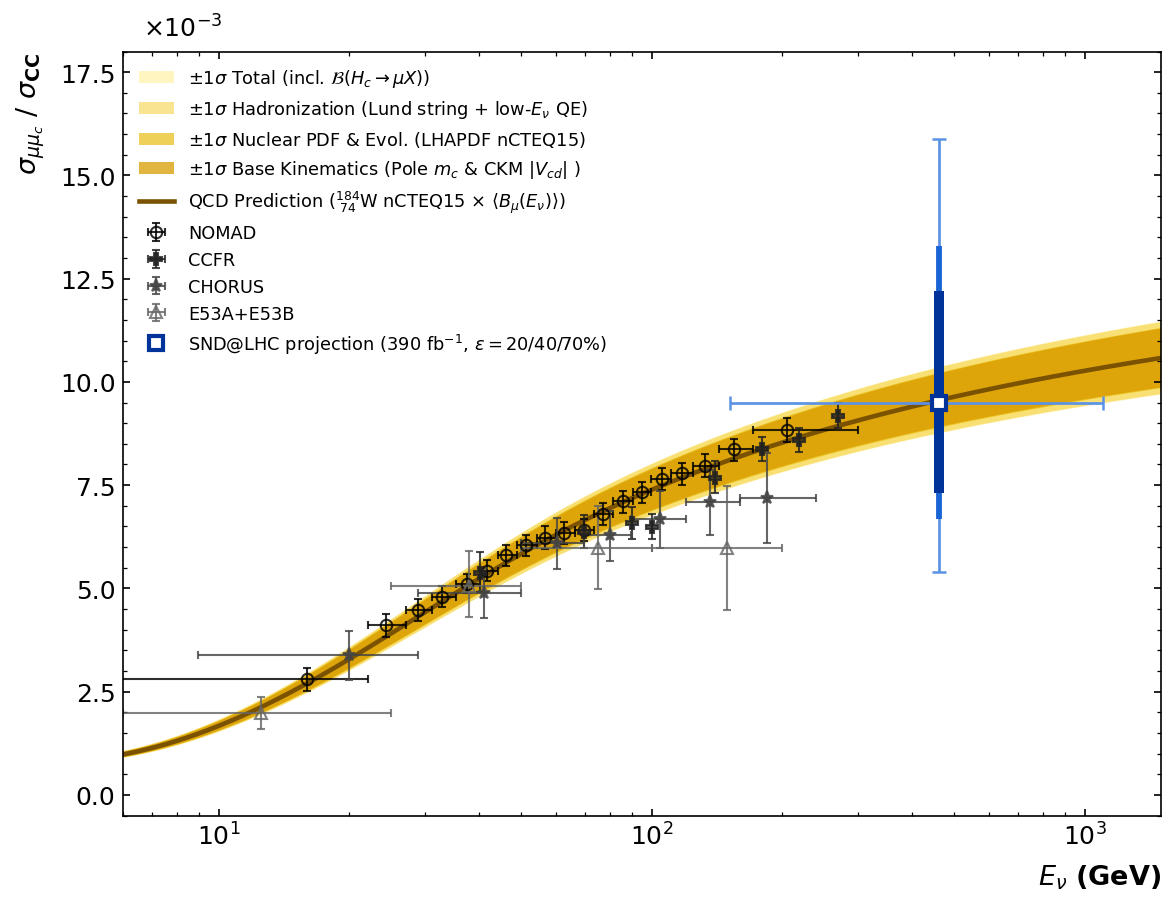

In [7]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 1. Load Precalculated Dimuon Predictions
# -------------------------------------------------------------------------
pred_csv = Path("/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/predictions/neutrino_charm_dimuon_ratio_nu_prediction_lhapdf.csv")
if not pred_csv.exists():
    pred_csv = Path("scripts/diagnostics/predictions/neutrino_charm_dimuon_ratio_nu_prediction_lhapdf.csv")

if not pred_csv.exists():
    raise FileNotFoundError(f"Could not find prediction CSV at {pred_csv}. Run calculation first.")

df_pred = pd.read_csv(pred_csv)

E_grid = df_pred["E_nu_GeV"].to_numpy()
y_nominal = df_pred["ratio_nominal_10m3"].to_numpy()
sigma_1_lo = df_pred["sigma_1_lo"].to_numpy()
sigma_1_hi = df_pred["sigma_1_hi"].to_numpy()
sigma_2_lo = df_pred["sigma_2_lo"].to_numpy()
sigma_2_hi = df_pred["sigma_2_hi"].to_numpy()
sigma_3_lo = df_pred["sigma_3_lo"].to_numpy()
sigma_3_hi = df_pred["sigma_3_hi"].to_numpy()
sigma_4_lo = df_pred["sigma_4_lo"].to_numpy()
sigma_4_hi = df_pred["sigma_4_hi"].to_numpy()

# -------------------------------------------------------------------------
# 2. Plotting Setup
# -------------------------------------------------------------------------
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 12,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.top': True, 'ytick.right': True,
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
})

fig, ax = plt.subplots(figsize=(8, 6.2), dpi=150)

c_line = '#7a5200'
c1, c2, c3, c4 = '#d99b00', '#e5b800', '#f5cf38', '#ffea75'

ax.fill_between(E_grid, y_nominal - sigma_4_lo, y_nominal + sigma_4_hi, color=c4, alpha=0.45, edgecolor='none', 
                label=r'$\pm 1\sigma$ Total (incl. $\mathcal{B}(H_c \to \mu X)$)')
ax.fill_between(E_grid, y_nominal - sigma_3_lo, y_nominal + sigma_3_hi, color=c3, alpha=0.55, edgecolor='none', 
                label=r'$\pm 1\sigma$ Hadronization (Lund string + low-$E_\nu$ QE)')
ax.fill_between(E_grid, y_nominal - sigma_2_lo, y_nominal + sigma_2_hi, color=c2, alpha=0.65, edgecolor='none', 
                label=r'$\pm 1\sigma$ Nuclear PDF & Evol. (LHAPDF nCTEQ15)')
ax.fill_between(E_grid, y_nominal - sigma_1_lo, y_nominal + sigma_1_hi, color=c1, alpha=0.75, edgecolor='none', 
                label=r'$\pm 1\sigma$ Base Kinematics (Pole $m_c$ & CKM $|V_{cd}|$ )')

ax.plot(E_grid, y_nominal, color=c_line, lw=2.2, linestyle='-', 
        label=r'QCD Prediction ($^{184}_{\ 74}\mathrm{W}$ nCTEQ15 $\times\ \langle B_\mu(E_\nu)\rangle$)')

# Overlays
styles = {
    'NOMAD': {'fmt': 'o', 'color': '#000000', 'mfc': 'none', 'ms': 5.5, 'label': 'NOMAD'},
    'CCFR': {'fmt': 'P', 'color': '#222222', 'mfc': '#222222', 'ms': 6.0, 'label': 'CCFR'},
    'CHORUS': {'fmt': '*', 'color': '#444444', 'mfc': '#444444', 'ms': 6.5, 'label': 'CHORUS'},
    'E53A+E53B': {'fmt': '^', 'color': '#666666', 'mfc': 'none', 'ms': 5.5, 'label': 'E53A+E53B'},
}

csv_path = '/afs/cern.ch/work/i/idioniso/snd-numu-charm/scripts/diagnostics/measurements/neutrino_charm_dimuon_ratio_vs_enu.csv'
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path, comment="#")
    for exp, sty in styles.items():
        sub = df[df['experiment'] == exp]
        ax.errorbar(sub['E_nu_GeV'], sub['ratio_times_10^-3'], xerr=[sub['dx_low'], sub['dx_high']], 
                    yerr=[sub['dy_low'], sub['dy_high']], fmt=sty['fmt'], color=sty['color'], 
                    mfc=sty['mfc'], markersize=sty['ms'], elinewidth=1.0, capsize=2, alpha=0.82, label=sty['label'])

E_snd, y_snd = 461.4, 9.48
dx_lo_snd, dx_hi_snd = 310.0, 640.0
c_real, c_opt, c_perf = '#5b92e5', '#1a65d6', '#003399'

ax.errorbar(E_snd, y_snd, xerr=[[dx_lo_snd], [dx_hi_snd]], yerr=[[4.09], [6.41]], 
            fmt='none', ecolor=c_real, elinewidth=1.3, capsize=3.5, capthick=1.2, zorder=6)
ax.errorbar(E_snd, y_snd, yerr=[[2.81], [3.81]], 
            fmt='none', ecolor=c_opt, elinewidth=2.8, capsize=0, zorder=7)
ax.errorbar(E_snd, y_snd, yerr=[[2.16], [2.71]], fmt='s', color=c_perf, mfc='white', 
            mec=c_perf, mew=2.0, markersize=6.8, elinewidth=4.8, capsize=0, zorder=8, 
            label=r'SND@LHC projection ($390\ \mathrm{fb}^{-1}$, $\varepsilon=20/40/70\%$)')

ax.set_xscale('log')
ax.set_xlim(6.0, 1500.0)
ax.set_ylim(-0.5, 18.0)
ax.set_xlabel(r'$E_{\nu}\ \mathbf{(GeV)}$', fontsize=13, loc='right', labelpad=6)
ax.set_ylabel(r'$\sigma_{\mu\mu_c}\ /\ \sigma_{\mathbf{CC}}$', fontsize=13, loc='top', labelpad=6)
ax.text(0.02, 1.02, r'$\times 10^{-3}$', transform=ax.transAxes, fontsize=12, fontweight='bold')
ax.legend(frameon=False, edgecolor='black', facecolor='white', framealpha=0.92, fontsize=8.5, loc='upper left')

plt.tight_layout()
plt.show()